## Programming the neural network (old)

Now that we have the math set up for a neural network, let's program this into Python. A specific programming paradigm suitable for this task would be to use Object Oriented Programming, which Python fully supports.

In [ ]:
import random
import numpy as np

In [ ]:
def relu(x):
    return max(0, x)

def d_relu(x):
    if x > 0:
        return 1
    else:
        return 0
    
def inv_relu(x):
    return x

In [ ]:
def sigmoid(x):
    return 1/(1 + np.exp(-x))

def d_sigmoid(x):
    return sigmoid(x) * (1 - sigmoid(x))
    
def inv_sigmoid(x):
    return x

In [ ]:
class NNStateError(ValueError):
    pass

class DimensionMismatch(ValueError):
    pass

In [ ]:
class NeuralNetwork:
    def __init__(self, neuron_lengths, sigma = 0.01, activation = relu, d_activation = d_relu, inv_activation = inv_relu):
        self.weights = []
        self.biases = []
        self.activation = np.vectorize(activation, otypes=[float])
        self.d_activation = np.vectorize(d_activation, otypes=[float])
        self.inv_activation = np.vectorize(inv_activation, otypes=[float])

        for layer in range(len(neuron_lengths) - 1):
            self.weights.append(np.random.normal(scale=sigma, size=(neuron_lengths[layer], neuron_lengths[layer+1])))
            self.biases.append(np.random.normal(scale=sigma, size=neuron_lengths[layer+1]))

    def valid_state(self):
        if len(self.weights) != len(self.biases):
            print(f"Warning: Weights and bias list lengths mismatch. You have {len(self.weights)} weight matrices and {len(self.biases)} bias vectors")
            return False
        for layer in range(len(self.weights)):
            if len(self.weights[layer].shape) != 2:
                print(f"Warning: Weight matrix at layer {layer+1} must be 2D array")
                return False
            if len(self.biases[layer].shape) != 1:
                print(f"Warning: Bias vector at layer {layer+1} must be 1D array")
                return False
            if self.weights[layer].shape[1] != self.biases[layer].shape[0]:
                print(f"Warning: Weight matrix and bias vector sizes mismatch at layer {layer+1}: {self.weights[layer].shape[1]} != {self.biases[layer].shape[0]}")
                return False
            if layer < len(self.weights) - 1:
                if self.weights[layer].shape[1] != self.weights[layer+1].shape[0]:
                    print(f"Warning: Weight matrix dimensions mismatch at layer {layer+1}: {self.weights[layer].shape[1]} != {self.weights[layer+1].shape[0]}")
                    return False
        return True

    def set_weight(self, layer, weights):
        self.weights[layer] = weights

    def set_bias(self, layer, bias):
        self.biases[layer] = bias

    def jitter(self, sigma=0.01):
        valid_state = self.valid_state()
        if not valid_state:
            raise NNStateError("Current neural network settings invalid. Please resolve printed error with set_weight or set_bias")
        
        for weight in self.weights:
            perturbation = np.random.normal(scale=sigma, size=weight.shape)
            weight += perturbation

        for bias in self.biases:
            perturbation = np.random.normal(scale=sigma, size=bias.shape)
            bias += perturbation

    def forward(self, input):
        valid_state = self.valid_state()
        if not valid_state:
            raise NNStateError("Current neural network settings invalid. Please resolve printed error with set_weight or set_bias")
        if type(input) != np.ndarray:
            raise TypeError("Input must be an array of dimension 1 or 2")
        if len(input.shape) == 1:
            if input.shape[0] != self.weights[0].shape[0]:
                raise DimensionMismatch(f"Input vector length mismatch: {input.shape[0]} != {self.weights[0].shape[0]}")
        elif len(input.shape) == 2:
            if input.shape[1] != self.weights[0].shape[0]:
                raise DimensionMismatch(f"Input array dimensions mismatch: {input.shape[1]} != {self.weights[0].shape[0]}")
        else:
            raise TypeError("Input must be an array of dimension 1 or 2")
        
        h_arrays = []
        z_arrays = []
        
        current_data = input

        h_arrays.append(current_data.copy())

        for layer in range(len(self.weights)):
            current_data = current_data @ self.weights[layer] + self.biases[layer]
            z_arrays.append(current_data.copy())
            current_data = self.activation(current_data)
            h_arrays.append(current_data.copy())

        return h_arrays, z_arrays
    
    def fit_final_layer(self, training_inputs, training_outputs, invert_activation = True):
        valid_state = self.valid_state()
        if not valid_state:
            raise NNStateError("Current neural network settings invalid. Please resolve printed error with set_weight or set_bias")
        if type(training_inputs) != np.ndarray or type(training_outputs) != np.ndarray:
            raise TypeError("Input and output must be 2D arrays. Height is number of data points")
        if len(training_inputs.shape) != 2 or len(training_outputs.shape) != 2:
            raise TypeError("Input and output must be 2D arrays. Height is number of data points")
        if training_inputs.shape[0] != training_outputs.shape[0]:
            raise DimensionMismatch(f"Height of training input data must match height of output data: {training_inputs.shape[0]} != {training_outputs.shape[0]}")
        if training_inputs.shape[1] != self.weights[0].shape[0]:
            raise DimensionMismatch(f"Input array dimensions mismatch: {training_inputs.shape[1]} != {self.weights[0].shape[0]}")
        if training_outputs.shape[1] != self.weights[-1].shape[1]:
            raise DimensionMismatch(f"Output array dimensions mismatch: {training_outputs.shape[1]} != {self.weights[-1].shape[1]}")
        
        h_arrays, z_arrays = self.forward(training_inputs)
        origin_neuron = h_arrays[-2]
        origin_neuron = np.hstack((origin_neuron, np.ones((origin_neuron.shape[0], 1))))
        if invert_activation == True:
            target_neuron = self.inv_activation(training_outputs)
        else:
            target_neuron = training_outputs

        matrix = np.linalg.lstsq(origin_neuron, target_neuron)[0]
        weight = matrix[:-1, :]
        bias = matrix[-1, :]

        self.set_weight(-1, weight)
        self.set_bias(-1, bias)

    def error(self, training_inputs, training_outputs, average=True):
        valid_state = self.valid_state()
        if not valid_state:
            raise NNStateError("Current neural network settings invalid. Please resolve printed error with set_weight or set_bias")
        if type(training_inputs) != np.ndarray or type(training_outputs) != np.ndarray:
            raise TypeError("Input and output must be arrays of same dimension 1 or 2")
        if len(training_inputs.shape) != len(training_outputs.shape):
            raise TypeError("Input and output must be arrays of same dimension 1 or 2")
        if len(training_inputs.shape) == 1:
            if training_inputs.shape[0] != self.weights[0].shape[0]:
                raise DimensionMismatch(f"Input vector length mismatch: {training_inputs.shape[0]} != {self.weights[0].shape[0]}")
            if training_outputs.shape[0] != self.weights[-1].shape[1]:
                raise DimensionMismatch(f"Output vector length mismatch: {training_outputs.shape[0]} != {self.weights[-1].shape[1]}")
        elif len(training_inputs.shape) == 2:
            if training_inputs.shape[0] != training_outputs.shape[0]:
                raise DimensionMismatch(f"Height of training input data must match height of output data: {training_inputs.shape[0]} != {training_outputs.shape[0]}")
            if training_inputs.shape[1] != self.weights[0].shape[0]:
                raise DimensionMismatch(f"Input array dimensions mismatch: {training_inputs.shape[1]} != {self.weights[0].shape[0]}")
            if training_outputs.shape[1] != self.weights[-1].shape[1]:
                raise DimensionMismatch(f"Output array dimensions mismatch: {training_outputs.shape[1]} != {self.weights[-1].shape[1]}")
        else:
            raise TypeError("Input and output must be arrays of same dimension 1 or 2")
        
        h_arrays, z_arrays = self.forward(training_inputs)

        total_squared_error = np.sum((h_arrays[-1] - training_outputs)**2)

        if average:
            total_squared_error /= training_inputs.shape[0]

        return total_squared_error

    def backpropagation(self, training_inputs, training_outputs, learning_rate=0.01, rel_noise=0, max_parameter_change = 0.1, average=True, apply=True):
        valid_state = self.valid_state()
        if not valid_state:
            raise NNStateError("Current neural network settings invalid. Please resolve printed error with set_weight or set_bias")
        if type(training_inputs) != np.ndarray or type(training_outputs) != np.ndarray:
            raise TypeError("Input and output must be arrays of same dimension 1 or 2")
        if len(training_inputs.shape) != len(training_outputs.shape):
            raise TypeError("Input and output must be arrays of same dimension 1 or 2")
        if len(training_inputs.shape) == 1:
            if training_inputs.shape[0] != self.weights[0].shape[0]:
                raise DimensionMismatch(f"Input vector length mismatch: {training_inputs.shape[0]} != {self.weights[0].shape[0]}")
            if training_outputs.shape[0] != self.weights[-1].shape[1]:
                raise DimensionMismatch(f"Output vector length mismatch: {training_outputs.shape[0]} != {self.weights[-1].shape[1]}")
        elif len(training_inputs.shape) == 2:
            if training_inputs.shape[0] != training_outputs.shape[0]:
                raise DimensionMismatch(f"Height of training input data must match height of output data: {training_inputs.shape[0]} != {training_outputs.shape[0]}")
            if training_inputs.shape[1] != self.weights[0].shape[0]:
                raise DimensionMismatch(f"Input array dimensions mismatch: {training_inputs.shape[1]} != {self.weights[0].shape[0]}")
            if training_outputs.shape[1] != self.weights[-1].shape[1]:
                raise DimensionMismatch(f"Output array dimensions mismatch: {training_outputs.shape[1]} != {self.weights[-1].shape[1]}")
        else:
            raise TypeError("Input and output must be arrays of same dimension 1 or 2")
        
        if len(training_inputs.shape) == 2:
            data_points = training_inputs.shape[0]
            total_weight_gradient = [np.zeros(array.shape) for array in self.weights]
            total_bias_gradient = [np.zeros(array.shape) for array in self.biases]
            for i in range(data_points):
                weight_gradient, bias_gradient = self.backpropagation(training_inputs[i, :], training_outputs[i, :], learning_rate=learning_rate, rel_noise=rel_noise, apply=False)
                for layer in range(len(weight_gradient)):
                    total_weight_gradient[layer] += weight_gradient[layer]
                for layer in range(len(bias_gradient)):
                    total_bias_gradient[layer] += bias_gradient[layer]
            if average:
                for layer in range(len(weight_gradient)):
                    total_weight_gradient[layer] /= data_points
                for layer in range(len(bias_gradient)):
                    total_bias_gradient[layer] /= data_points
        else:
            h_arrays, z_arrays = self.forward(training_inputs)

            error_gradient = 2 * (h_arrays[-1] - training_outputs)
            error_signals = [error_gradient]
            for layer in range(len(self.weights)-1, 0, -1):
                f_jacobian = np.diag(self.d_activation(z_arrays[layer]))
                g_jacobian = self.weights[layer] @ f_jacobian
                error_signals.insert(0, (g_jacobian @ error_signals[0]).copy())
            total_weight_gradient = []
            total_bias_gradient = []

            for layer in range(len(error_signals)):
                total_bias_gradient.append(self.d_activation(z_arrays[layer]) * error_signals[layer])
                total_weight_gradient.append(np.outer(h_arrays[layer], total_bias_gradient[layer]))

        for layer in range(len(total_weight_gradient)):
            total_weight_gradient[layer] += np.random.normal(scale=rel_noise, size=total_weight_gradient[layer].shape)
            total_weight_gradient[layer] = np.clip(total_weight_gradient[layer], -max_parameter_change, max_parameter_change)
        for layer in range(len(total_bias_gradient)):
            total_bias_gradient[layer] += np.random.normal(scale=rel_noise, size=total_bias_gradient[layer].shape)
            total_bias_gradient[layer] = np.clip(total_bias_gradient[layer], -max_parameter_change, max_parameter_change)

        if apply:
            for layer in range(len(total_weight_gradient)):
                self.weights[layer] -= total_weight_gradient[layer] * learning_rate
            for layer in range(len(total_bias_gradient)):
                self.biases[layer] -= total_bias_gradient[layer] * learning_rate
        return total_weight_gradient, total_bias_gradient

Now let's test out some functions to see that our code is working. We take the following neural network as an example, the first cell initializes the network:

In [ ]:
nn1 = NeuralNetwork([784, 50, 40, 30, 30, 10], sigma=0.1)

In [ ]:
nn1.set_bias(0, np.random.normal(scale=0.1, size=(70,)))
print(nn1.valid_state())

False


In [ ]:
nn1.set_weight(1, np.random.normal(scale=0.1, size=(60, 40)))
print(nn1.valid_state())

False


Oops! If we change the weight matrix or bias vector to a random size, we get this error message due to a dimension mismatch. But if we ensure our dimensions are correct, we should not show any issues.

In [ ]:
nn1.set_bias(0, np.random.normal(scale=0.1, size=(50,)))
print(nn1.valid_state())

True


In [ ]:
nn1.set_weight(1, np.random.normal(scale=0.1, size=(50, 40)))
print(nn1.valid_state())

True


Now, let's try running some toy input data through the neural network, using the forward method.

In [ ]:
input_data = np.random.normal(scale=0.1, size=(20, 784))
output_data = nn1.forward(input_data)

In [ ]:
[array.shape for array in output_data[1]]

[(20, 50), (20, 40), (20, 30), (20, 30), (20, 10)]

Let's test the backpropagation method to see if it returns what we want. We will test with some toy training data.

In [ ]:
input_data = np.random.normal(scale=1, size=(80, 784))
output_data = np.random.normal(scale=1, size=(80, 10))

In [ ]:
for i in range(100):
    print(nn1.error(input_data, output_data))
    nn1.backpropagation(input_data, output_data, learning_rate=0.1, rel_noise = 0.1)

9.471798733553168
9.451487546235294
9.419566075970469
9.399594419888128
9.373647707729237
9.356871581149198
9.349715464564065
9.321071920285203
9.298507576183859
9.286150022065785
9.284808553386913
9.270706658945096
9.2544117284375
9.243893484158667
9.234187127400208
9.223000636442848
9.200312909069293
9.19659890880869
9.18254623042257
9.18295784884531
9.16667657825171
9.142767031773987
9.11469555802808
9.094654950400866
9.101520608723437
9.104166176201621
9.099529966111485
9.060737537234978
9.053004695035582
9.033073809803316
9.015079736667069
9.00459601904873
8.970560125012245
8.952675510481646
8.903872169652335
8.891402298873846
8.893866765847724
8.8802142647667
8.858953690090459
8.855406426865187
8.813721202284142
8.78969698127778
8.787394884156438
8.770153345185808
8.751742360371034
8.723252257824225
8.722274043376816
8.721676503449356
8.686025279079008
8.666097712968073
8.679989692601248
8.654722729282975
8.652679211273544
8.624453407197048
8.610272787997696
8.548179371009697
8.5

Let's see if fitting the final layer first produces better results.

In [ ]:
nn1.fit_final_layer(input_data, output_data)

C:\Users\rayng\AppData\Local\Temp\ipykernel_36856\3255122215.py:102: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  matrix = np.linalg.lstsq(origin_neuron, target_neuron)[0]


In [ ]:
for i in range(100):
    print(nn1.error(input_data, output_data))
    nn1.backpropagation(input_data, output_data, learning_rate=0.01, rel_noise = 0.1)

6.306281159428401
6.284053549111824
6.263568922784549
6.252121713903034
6.229983079344419
6.218644250013687
6.201112701062867
6.1797793050558
6.169568109865264
6.148669148980027
6.144174531465204
6.128548014927366
6.114760719510558
6.100018118797001
6.089871954132176
6.078562882972331
6.05964409807463
6.04294073451153
6.040550872756485
6.030679226449327
6.012609822773023
5.998605756759363
5.985917531158765
5.975919892756515
5.969472378911116
5.961315179581385
5.951523936334498
5.939483990280804
5.924551216182417
5.918809132976196
5.910083586120492
5.8991355779460175
5.891731379662101
5.878675856990809
5.866037016667141
5.847579250010985
5.831410342095522
5.823362466954393
5.812834291418359
5.803888485109873
5.789720253886655
5.780033317720598
5.773673427679275
5.763397198311049
5.7522595166682065
5.743901244075751
5.735943543469167
5.736989129837158
5.731838822420802
5.724937633208296
5.724260050430405
5.708286499667343
5.706781998727552
5.702274002118971
5.697111962056612
5.6931140210

Then the average error immediately decreases, which is what we want.

Looking at this result, it generally shows a decreasing trend in our error. That means our learning function is working as intended. However, if our learning rate is too high, it risks overshooting the training at a step and actually increasing the error, even exploding the error. That's why, as a potential solution, we could try clipping the weight and bias perturbations within a certain limit of $\pm k$.

Now our next step is to import some data. The moment we are waiting for. Let's fetch the data for the MNIST handwritten digits. Data is available to download at https://www.kaggle.com/datasets/hojjatk/mnist-dataset?resource=download. The following code has been copied from https://www.kaggle.com/code/hojjatk/read-mnist-dataset :

In [ ]:
#
# This is a sample Notebook to demonstrate how to read "MNIST Dataset"
#
import numpy as np # linear algebra
import struct
from array import array
from os.path  import join

#
# MNIST Data Loader Class
#
class MnistDataloader(object):
    def __init__(self, training_images_filepath,training_labels_filepath,
                 test_images_filepath, test_labels_filepath):
        self.training_images_filepath = training_images_filepath
        self.training_labels_filepath = training_labels_filepath
        self.test_images_filepath = test_images_filepath
        self.test_labels_filepath = test_labels_filepath
    
    def read_images_labels(self, images_filepath, labels_filepath):        
        labels = []
        with open(labels_filepath, 'rb') as file:
            magic, size = struct.unpack(">II", file.read(8))
            if magic != 2049:
                raise ValueError('Magic number mismatch, expected 2049, got {}'.format(magic))
            labels = array("B", file.read())        
        
        with open(images_filepath, 'rb') as file:
            magic, size, rows, cols = struct.unpack(">IIII", file.read(16))
            if magic != 2051:
                raise ValueError('Magic number mismatch, expected 2051, got {}'.format(magic))
            image_data = array("B", file.read())        
        images = []
        for i in range(size):
            images.append([0] * rows * cols)
        for i in range(size):
            img = np.array(image_data[i * rows * cols:(i + 1) * rows * cols])
            img = img.reshape(28, 28)
            images[i][:] = img            
        
        return images, labels
            
    def load_data(self):
        x_train, y_train = self.read_images_labels(self.training_images_filepath, self.training_labels_filepath)
        x_test, y_test = self.read_images_labels(self.test_images_filepath, self.test_labels_filepath)
        return (x_train, y_train),(x_test, y_test)

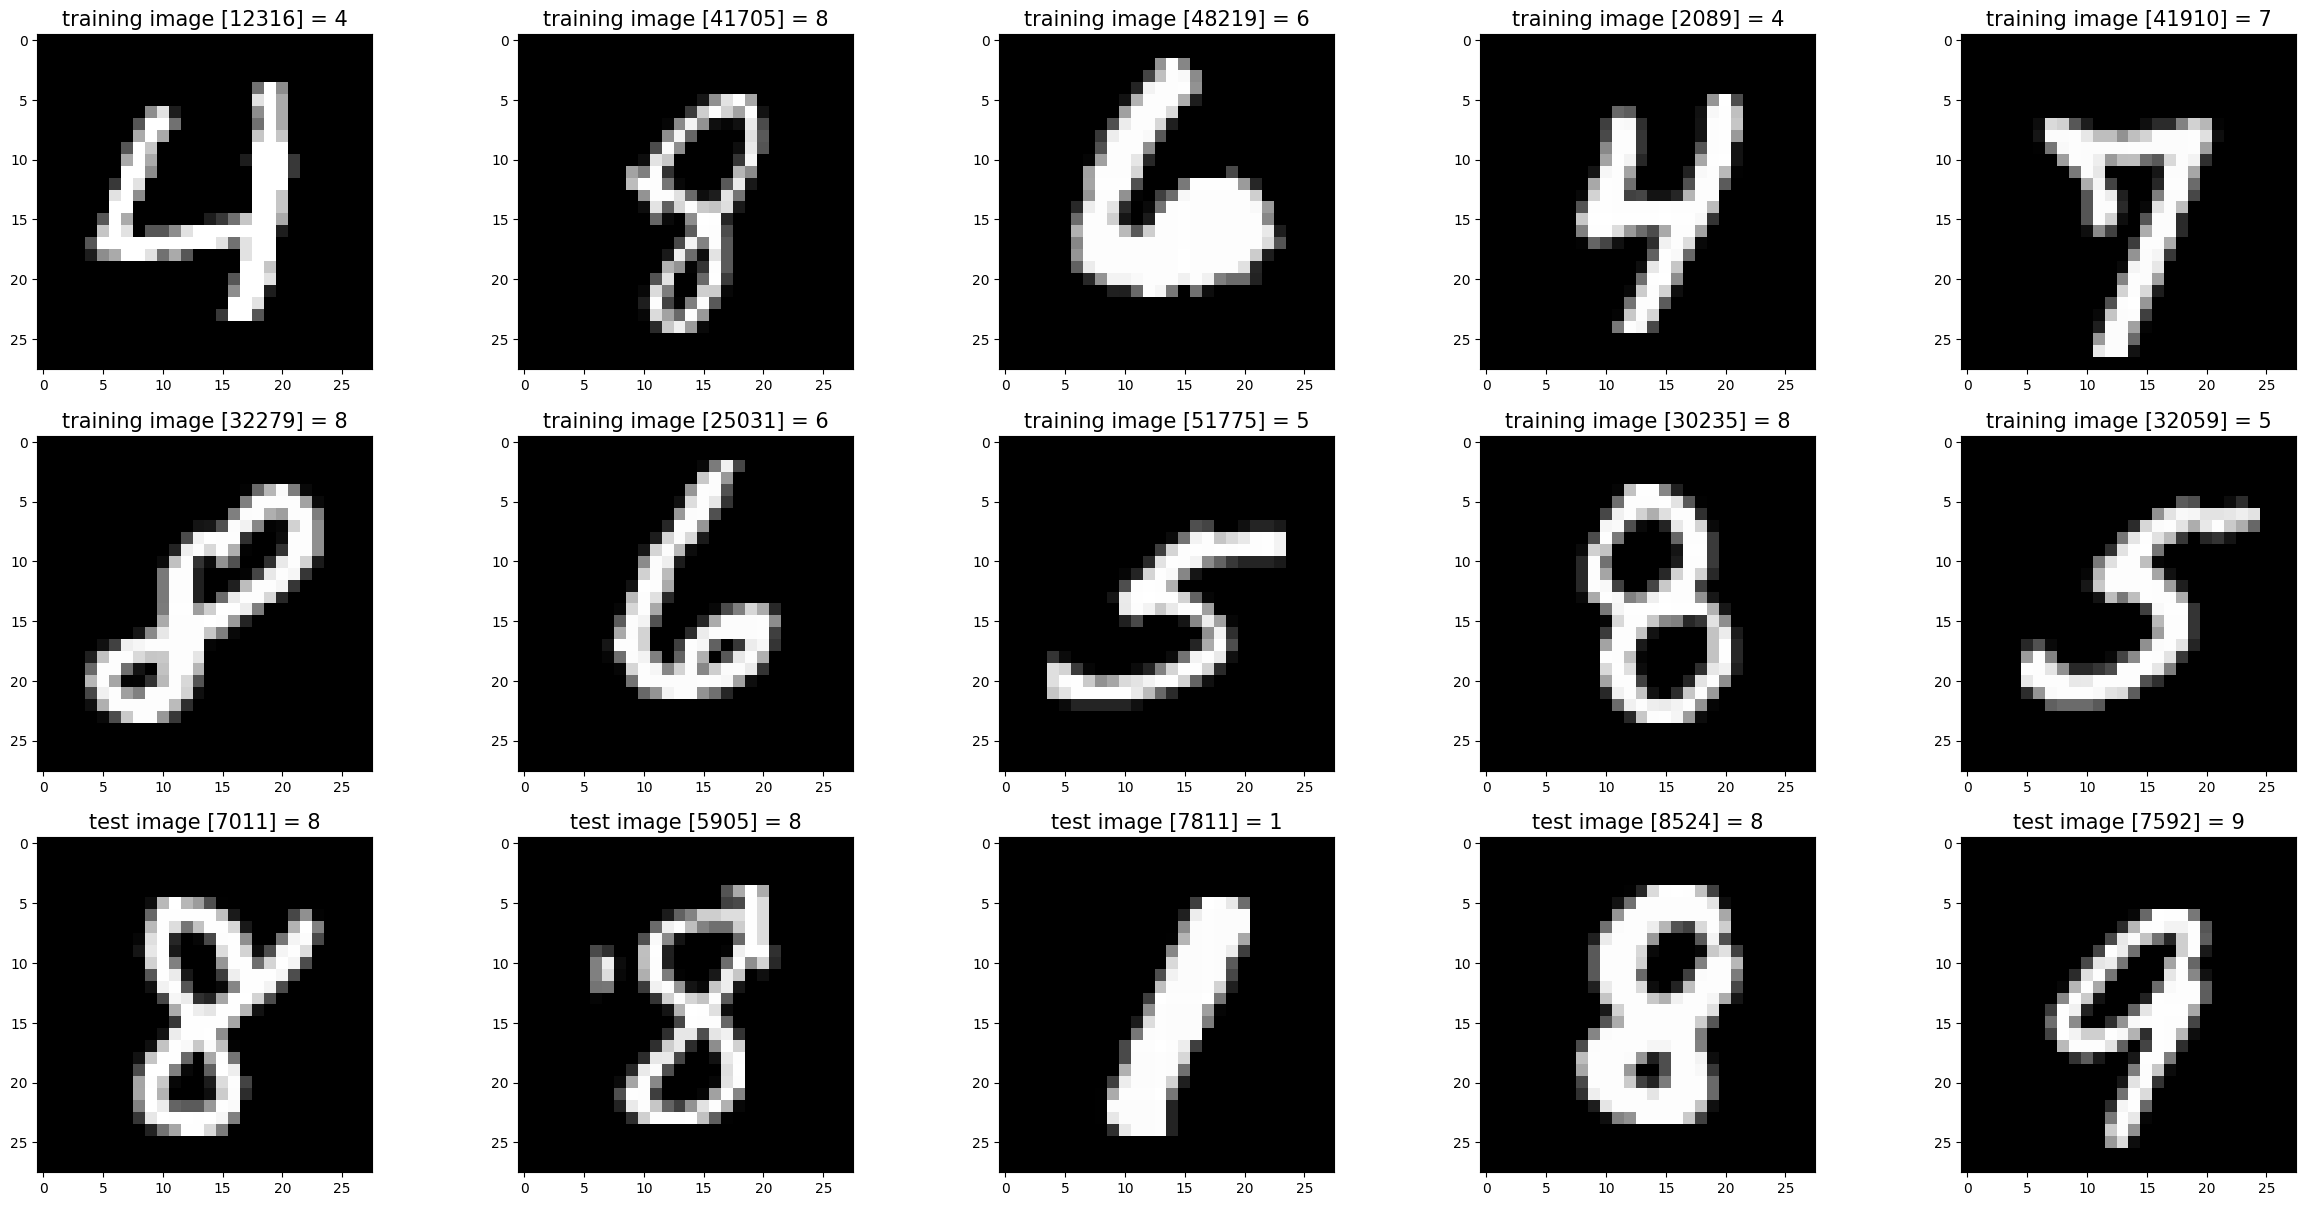

In [ ]:
#
# Verify Reading Dataset via MnistDataloader class
#
%matplotlib inline
import random
import matplotlib.pyplot as plt

#
# Set file paths based on added MNIST Datasets
#
input_path = 'mnist'
training_images_filepath = join(input_path, 'train-images-idx3-ubyte/train-images-idx3-ubyte')
training_labels_filepath = join(input_path, 'train-labels-idx1-ubyte/train-labels-idx1-ubyte')
test_images_filepath = join(input_path, 't10k-images-idx3-ubyte/t10k-images-idx3-ubyte')
test_labels_filepath = join(input_path, 't10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte')

#
# Helper function to show a list of images with their relating titles
#
def show_images(images, title_texts):
    cols = 5
    rows = int(len(images)/cols) + 1
    plt.figure(figsize=(30,20))
    index = 1    
    for x in zip(images, title_texts):        
        image = x[0]        
        title_text = x[1]
        plt.subplot(rows, cols, index)        
        plt.imshow(image, cmap=plt.cm.gray)
        if (title_text != ''):
            plt.title(title_text, fontsize = 15);        
        index += 1

#
# Load MINST dataset
#
mnist_dataloader = MnistDataloader(training_images_filepath, training_labels_filepath, test_images_filepath, test_labels_filepath)
(x_train, y_train), (x_test, y_test) = mnist_dataloader.load_data()

#
# Show some random training and test images 
#
images_2_show = []
titles_2_show = []
for i in range(0, 10):
    r = random.randint(1, 60000)
    images_2_show.append(x_train[r])
    titles_2_show.append('training image [' + str(r) + '] = ' + str(y_train[r]))    

for i in range(0, 5):
    r = random.randint(1, 10000)
    images_2_show.append(x_test[r])        
    titles_2_show.append('test image [' + str(r) + '] = ' + str(y_test[r]))    

show_images(images_2_show, titles_2_show)

In [ ]:
x_train[0][5]

array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
        18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
         0,   0], dtype=uint8)

In [ ]:
y_train[0]

5

Once we got our data, we need to work to convert the training data into what we can feed into our neural network. The variables `x_train`, `y_train`, `x_test`, and `y_test` get loaded onto our terminal where the `x` data is shown as a list of all the image data, a list of 28 arrays of length 28 in each entry in this list, and `y` is the corresponding digit. We need to transform this data to what can be used to feed into our neural network.

In [ ]:
x_train_array = np.stack([np.concatenate(arrays) for arrays in x_train]) / 255
x_test_array = np.stack([np.concatenate(arrays) for arrays in x_test]) / 255

In [ ]:
y_train_array = np.zeros((60000, 10))

for i in range(60000):
    digit = y_train[i]
    y_train_array[i, digit] = 1

y_test_array = np.zeros((10000, 10))

for i in range(10000):
    digit = y_test[i]
    y_test_array[i, digit] = 1

Let's make some strokes. These are features we want to detect in our image, and will be used as a heuristic for our first layer's weights. The set of strokes will be a mix of horizontal, vertical, and diagonal strokes starting at different positions.

In [ ]:
def stroke(thickness, length, direction, start_x, start_y):
    # thickness: size of square of each dot
    # length: number of dots placed
    # direction: 0 for right, 1 for diagonal down right, 2 for down, 3 for diagonal down left
    # start_x, start_y: top-left coordinate of starting stroke

    if direction == 0:
        image_left = start_x
        image_right = start_x + (thickness - 1) + (length - 1)
        image_top = start_y
        image_bottom = start_y + (thickness - 1)
    elif direction == 1:
        image_left = start_x
        image_right = start_x + (thickness - 1) + (length - 1)
        image_top = start_y
        image_bottom = start_y + (thickness - 1) + (length - 1)
    elif direction == 2:
        image_left = start_x
        image_right = start_x + (thickness - 1)
        image_top = start_y
        image_bottom = start_y + (thickness - 1) + (length - 1)
    elif direction == 3:
        image_left = start_x - (length - 1)
        image_right = start_x + (thickness - 1)
        image_top = start_y
        image_bottom = start_y + (thickness - 1) + (length - 1)

    if not (0 <= image_left <= 27):
        raise ValueError("Image out of bounds")
    if not (0 <= image_right <= 27):
        raise ValueError("Image out of bounds")
    if not (0 <= image_top <= 27):
        raise ValueError("Image out of bounds")
    if not (0 <= image_bottom <= 27):
        raise ValueError("Image out of bounds")

    image = np.zeros((28,28))

    current_x = start_x
    current_y = start_y

    for i in range(length):
        image[current_y:current_y+thickness, current_x:current_x+thickness] = 1
        if direction == 0:
            current_x += 1
        elif direction == 1:
            current_x += 1
            current_y += 1
        elif direction == 2:
            current_y += 1
        elif direction == 3:
            current_x -= 1
            current_y += 1

    return image.reshape(784)

In [ ]:
stroke(3, 8, 0, 18, 18)

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

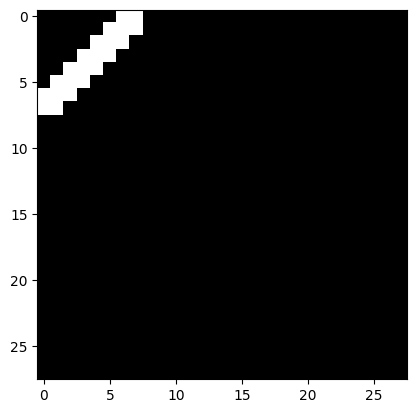

In [ ]:
stroke_sample = np.reshape(stroke(2, 7, 3, 6, 0), (28, 28))
plt.imshow(stroke_sample, cmap=plt.cm.gray)

In [ ]:
stroke_set = []

for x in range(0, 28, 2):
    for y in range(0, 28, 2):
        try:
            stroke_sample = stroke(2, 7, 0, x, y)
            stroke_set.append(stroke_sample)
        except:
            pass
        try:
            stroke_sample = stroke(2, 7, 1, x, y)
            stroke_set.append(stroke_sample)
        except:
            pass
        try:
            stroke_sample = stroke(2, 7, 2, x, y)
            stroke_set.append(stroke_sample)
        except:
            pass
        try:
            stroke_sample = stroke(2, 7, 3, x, y)
            stroke_set.append(stroke_sample)
        except:
            pass

In [ ]:
stroke_set_array = np.stack(stroke_set).transpose().copy()

In [ ]:
stroke_set_array.shape

(784, 550)

Now, we'll get to set up our neural network with the initial parameters, and weight set. A good number of neurons to use might be 784, 550, 100, 40, and 10 from the input to the output.

In [ ]:
mnist_nn = NeuralNetwork([784, 550, 100, 40, 10], sigma=0.1)

mnist_nn.set_weight(0, stroke_set_array)

In [ ]:
mnist_nn.weights

[array([[1., 1., 1., ..., 0., 0., 0.],
        [1., 1., 1., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 1., 0.],
        [0., 0., 0., ..., 0., 1., 0.]]),
 array([[-0.05428687,  0.09652893,  0.07536584, ..., -0.12581028,
         -0.17112647, -0.02205355],
        [ 0.14883714, -0.0689174 ,  0.13988076, ...,  0.06710139,
          0.11054537,  0.09017258],
        [ 0.02017738,  0.00138047, -0.02771956, ..., -0.01561343,
         -0.1911508 , -0.21964103],
        ...,
        [-0.03240696, -0.02886567,  0.08284719, ..., -0.01600043,
         -0.1211968 ,  0.03087796],
        [-0.13235838, -0.09179598,  0.07939685, ...,  0.13434547,
         -0.02482456,  0.02015116],
        [ 0.17917186,  0.09676326, -0.03771726, ..., -0.21603107,
         -0.12662693,  0.14932884]]),
 array([[ 0.0112267 ,  0.05635706,  0.03524949, ..., -0.11615578,
         -0.02509692, -0.20291348],
        [ 0.12751964, 

Let's extract a random set of indices from our training data of 60,000 to fit the final layer's weight and bias. That way our training will initialize closely by correlation at the final layer. Then what we'll do next is to backpropagate by the gradient descent using smaller, randomized batches, while monitoring the error with a certain subset of the test set.

In [ ]:
indices = np.random.choice(range(60000), size=1000, replace=False)

initial_training_x = x_train_array[indices, :]
initial_training_y = y_train_array[indices, :]

In [ ]:
mnist_nn.fit_final_layer(initial_training_x, initial_training_y)

C:\Users\rayng\AppData\Local\Temp\ipykernel_36856\3255122215.py:102: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  matrix = np.linalg.lstsq(origin_neuron, target_neuron)[0]


In [ ]:
test_indices = np.random.choice(range(10000), size=100, replace=False)

testing_sample_x = x_test_array[test_indices, :]
testing_sample_y = y_test_array[test_indices, :]

In [ ]:
print(mnist_nn.error(testing_sample_x, testing_sample_y))

0.4826573661837405


A pretty good average error for the testing sample. Let's see how this same error changes over time if we backpropagate against random samples.

In [ ]:
for i in range(100):
    sample_indices = np.random.choice(range(60000), size=20, replace=False)
    training_sample_x = x_train_array[sample_indices, :]
    training_sample_y = y_train_array[sample_indices, :]
    mnist_nn.backpropagation(training_sample_x, training_sample_y)
    print(f"Training iteration {i+1}:")
    print(f"Average error: {mnist_nn.error(testing_sample_x, testing_sample_y)}")

Training iteration 1:
Average error: 0.4720901366004705
Training iteration 2:
Average error: 0.4719126949832767
Training iteration 3:
Average error: 0.4720299237412353
Training iteration 4:
Average error: 0.48115139711005717
Training iteration 5:
Average error: 0.47931372758529067
Training iteration 6:
Average error: 0.4905879596419308
Training iteration 7:
Average error: 0.5049319721360658
Training iteration 8:
Average error: 0.5152971258243483
Training iteration 9:
Average error: 0.5257117021642231
Training iteration 10:
Average error: 0.5291315772551973
Training iteration 11:
Average error: 0.5521966065577429
Training iteration 12:
Average error: 0.5528329765416623
Training iteration 13:
Average error: 0.539870456344476
Training iteration 14:
Average error: 0.5421391616326414
Training iteration 15:
Average error: 0.529921155820446
Training iteration 16:
Average error: 0.5279475589947767
Training iteration 17:
Average error: 0.5222744714424747
Training iteration 18:
Average error: 0.

Turns out the error against the test set has fluctuated a lot instead of decreased. Should we slow down the learning rate, or increase our training batch size? Maybe this is the network learning new things.

In [ ]:
for i in range(100):
    sample_indices = np.random.choice(range(60000), size=20, replace=False)
    training_sample_x = x_train_array[sample_indices, :]
    training_sample_y = y_train_array[sample_indices, :]
    mnist_nn.backpropagation(training_sample_x, training_sample_y, learning_rate = 0.001)
    print(f"Training iteration {i+1}:")
    print(f"Average error: {mnist_nn.error(testing_sample_x, testing_sample_y)}")

Training iteration 1:
Average error: 2.1430056070468275
Training iteration 2:
Average error: 2.1718247142078337
Training iteration 3:
Average error: 2.1000276790464985
Training iteration 4:
Average error: 2.016719521150415
Training iteration 5:
Average error: 2.0507275616399143
Training iteration 6:
Average error: 2.005912689226679
Training iteration 7:
Average error: 2.0037799766869044
Training iteration 8:
Average error: 2.038122280151392
Training iteration 9:
Average error: 2.108233449394203
Training iteration 10:
Average error: 2.1412884594623667
Training iteration 11:
Average error: 2.1005231531652635
Training iteration 12:
Average error: 2.1301937893739615
Training iteration 13:
Average error: 2.0761894210108585
Training iteration 14:
Average error: 2.1066039303895354
Training iteration 15:
Average error: 2.0687882676355738
Training iteration 16:
Average error: 2.0822663720301566
Training iteration 17:
Average error: 1.9960934827685808
Training iteration 18:
Average error: 1.9892

Doesn't seem to have decreased significantly. Maybe we should increase our training batch size so it's more representative. It's going to be slower with the larger sample size.

In [ ]:
for i in range(100):
    sample_indices = np.random.choice(range(60000), size=50, replace=False)
    training_sample_x = x_train_array[sample_indices, :]
    training_sample_y = y_train_array[sample_indices, :]
    mnist_nn.backpropagation(training_sample_x, training_sample_y, learning_rate = 0.001)
    print(f"Training iteration {i+1}:")
    print(f"Average error: {mnist_nn.error(testing_sample_x, testing_sample_y)}")

Training iteration 1:
Average error: 1.942781949097556
Training iteration 2:
Average error: 1.946587694451585
Training iteration 3:
Average error: 1.9067226781482858
Training iteration 4:
Average error: 1.8828088306814508
Training iteration 5:
Average error: 1.9166195190395052
Training iteration 6:
Average error: 1.9223625217466083
Training iteration 7:
Average error: 1.9047720731442173
Training iteration 8:
Average error: 1.906590439795031
Training iteration 9:
Average error: 1.9046795062395543
Training iteration 10:
Average error: 1.852806834178178
Training iteration 11:
Average error: 1.8156004454151529
Training iteration 12:
Average error: 1.8364135337892864
Training iteration 13:
Average error: 1.8698453769274976
Training iteration 14:
Average error: 1.87101943182192
Training iteration 15:
Average error: 1.874625694797017
Training iteration 16:
Average error: 1.880780463469349
Training iteration 17:
Average error: 1.9046686292805055
Training iteration 18:
Average error: 1.91774652

Again, not a great decrease, but there's a decreasing trend. Tell us the error function is probably quite rough and irregular that it frequently overshoots. How about this: Let's run for many more iterations, decrease the learning rate significantly, and keep the batch size small for efficiency.

In [ ]:
for i in range(1000):
    sample_indices = np.random.choice(range(60000), size=20, replace=False)
    training_sample_x = x_train_array[sample_indices, :]
    training_sample_y = y_train_array[sample_indices, :]
    mnist_nn.backpropagation(training_sample_x, training_sample_y, learning_rate = 0.0001)
    print(f"Training iteration {i+1}:")
    print(f"Average error: {mnist_nn.error(testing_sample_x, testing_sample_y)}")

Training iteration 1:
Average error: 1.7873466422477526
Training iteration 2:
Average error: 1.7839841728961572
Training iteration 3:
Average error: 1.785250841214459
Training iteration 4:
Average error: 1.787509628309694
Training iteration 5:
Average error: 1.7915808619382394
Training iteration 6:
Average error: 1.7852894153873098
Training iteration 7:
Average error: 1.7899935917191483
Training iteration 8:
Average error: 1.7833130991141726
Training iteration 9:
Average error: 1.7854187472054048
Training iteration 10:
Average error: 1.7813411591924853
Training iteration 11:
Average error: 1.786733610822229
Training iteration 12:
Average error: 1.7884663079910093
Training iteration 13:
Average error: 1.7886452820782663
Training iteration 14:
Average error: 1.791563948360145
Training iteration 15:
Average error: 1.7751302725615241
Training iteration 16:
Average error: 1.7791636191371702
Training iteration 17:
Average error: 1.7714117020648168
Training iteration 18:
Average error: 1.7722

If you watch this, you can see there's a slow but steady downward trend in the error. But it's still not as significant as we would ideally like it to be. Maybe let's introduce a bit of chaos by ading some noise to the mix. Could this possibly find a lower valley a little faster?

In [ ]:
for i in range(1000):
    sample_indices = np.random.choice(range(60000), size=20, replace=False)
    training_sample_x = x_train_array[sample_indices, :]
    training_sample_y = y_train_array[sample_indices, :]
    mnist_nn.backpropagation(training_sample_x, training_sample_y, learning_rate = 0.0001, rel_noise = 0.001)
    print(f"Training iteration {i+1}:")
    print(f"Average error: {mnist_nn.error(testing_sample_x, testing_sample_y)}")

Training iteration 1:
Average error: 1.5347614368833482
Training iteration 2:
Average error: 1.5357833477386453
Training iteration 3:
Average error: 1.5284627997145137
Training iteration 4:
Average error: 1.5308117398417682
Training iteration 5:
Average error: 1.5325352671159118
Training iteration 6:
Average error: 1.5372644510189821
Training iteration 7:
Average error: 1.5387161859279874
Training iteration 8:
Average error: 1.5369649783016965
Training iteration 9:
Average error: 1.536006237308104
Training iteration 10:
Average error: 1.5348784727231
Training iteration 11:
Average error: 1.5321389426365917
Training iteration 12:
Average error: 1.5345113734117333
Training iteration 13:
Average error: 1.5296659999070585
Training iteration 14:
Average error: 1.5315749421016678
Training iteration 15:
Average error: 1.5337616244558696
Training iteration 16:
Average error: 1.5316968522589063
Training iteration 17:
Average error: 1.527401421274624
Training iteration 18:
Average error: 1.52590

Turns out that adding some noise is not really helping our error decrease, as it has more like flatlined. Though at later iterations we could say it has started decreasing, at least so it seems. Maybe decreasing the learning error helps? Or how about... we shake things up (literally) by adding some jitter to our weight and bias parameters? Let's first take a look at what's up with the weights and biases of our neural network.

array([ 1.00000575e+00,  9.99996927e-01,  1.00000037e+00, -7.67141400e-06,
        2.10185279e-06, -2.72669972e-06, -1.37977502e-07, -5.01662987e-06,
        1.49324055e-06, -6.51116813e-06,  3.20362905e-06,  1.50276831e-06,
       -2.26063109e-06, -1.35063077e-06, -3.90292480e-06,  3.70380978e-06,
       -2.18760397e-07,  5.59902663e-06, -3.54601847e-06,  7.42706422e-07,
       -9.17333667e-07, -3.85658778e-07, -6.10786436e-06, -1.92902108e-06,
       -1.75549022e-06, -1.44233331e-06, -7.76747110e-06, -3.34153219e-06,
       -6.31204443e-07, -9.14241827e-06, -3.55389971e-06,  4.37204193e-06,
       -2.35409174e-06,  6.34983612e-07, -1.00199329e-05,  1.72527772e-06,
       -7.04974744e-07,  1.02839118e-06,  3.58669129e-06, -1.76034120e-06,
        4.28196415e-07, -1.00641577e-07, -1.52208076e-06,  1.26977942e-06,
       -2.48869665e-06, -2.99656377e-06, -2.90475996e-06, -4.11422199e-06,
        6.57119769e-07, -5.54999491e-06,  1.80917831e-06, -2.38185544e-06,
        7.56277470e-07,  

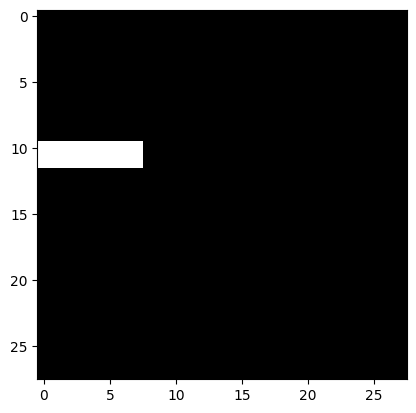

In [ ]:
stroke_sample = np.reshape(mnist_nn.weights[0][:, 15], (28, 28))
plt.imshow(stroke_sample, cmap=plt.cm.gray)
mnist_nn.weights[0][0, :]

Turns out our stroke layer has not changed. Should we try, for example, doing more aggressive learning? Risky but it could potentially get us where we want.

In [ ]:
for i in range(100):
    sample_indices = np.random.choice(range(60000), size=50, replace=False)
    training_sample_x = x_train_array[sample_indices, :]
    training_sample_y = y_train_array[sample_indices, :]
    mnist_nn.backpropagation(training_sample_x, training_sample_y, learning_rate = 0.01, rel_noise = 0.01)
    print(f"Training iteration {i+1}:")
    print(f"Average error: {mnist_nn.error(testing_sample_x, testing_sample_y)}")

Training iteration 1:
Average error: 1.6297882714527907
Training iteration 2:
Average error: 1.2427000062551894
Training iteration 3:
Average error: 1.2567420046980706
Training iteration 4:
Average error: 0.9690945433830019
Training iteration 5:
Average error: 1.0749707341332826
Training iteration 6:
Average error: 0.9004288180613265
Training iteration 7:
Average error: 0.7848448089828889
Training iteration 8:
Average error: 0.937715282573955
Training iteration 9:
Average error: 1.2296330088486487
Training iteration 10:
Average error: 1.384133935843123
Training iteration 11:
Average error: 1.159119679654191
Training iteration 12:
Average error: 1.2987013107626129
Training iteration 13:
Average error: 1.3917996889985316
Training iteration 14:
Average error: 1.4373125906028996
Training iteration 15:
Average error: 1.4866493627131137
Training iteration 16:
Average error: 1.6457457172250864
Training iteration 17:
Average error: 1.714037315782421
Training iteration 18:
Average error: 1.6985

Surprisingly, it turns out we halved the error by increasing the learning rate. But there's a caveat in that there are a lot of fluctuations. To go further, at this low point, we can continue training with a slower learning rate. Or we can take another risk to increase the learning rate a bit more, considering the results of this performance.

In [ ]:
for i in range(100):
    sample_indices = np.random.choice(range(60000), size=50, replace=False)
    training_sample_x = x_train_array[sample_indices, :]
    training_sample_y = y_train_array[sample_indices, :]
    mnist_nn.backpropagation(training_sample_x, training_sample_y, learning_rate = 0.05, rel_noise = 0.01)
    print(f"Training iteration {i+1}:")
    print(f"Average error: {mnist_nn.error(testing_sample_x, testing_sample_y)}")

Training iteration 1:
Average error: 0.5915034897977565
Training iteration 2:
Average error: 0.8501628612365926
Training iteration 3:
Average error: 0.6432944131014742
Training iteration 4:
Average error: 0.6375451491991413
Training iteration 5:
Average error: 0.593684048407869
Training iteration 6:
Average error: 0.5571030667748712
Training iteration 7:
Average error: 0.5476295221781083
Training iteration 8:
Average error: 0.5573253137012224
Training iteration 9:
Average error: 0.6169968798623836
Training iteration 10:
Average error: 1.3814080927750028
Training iteration 11:
Average error: 0.5666918396598116
Training iteration 12:
Average error: 0.5520189740145416
Training iteration 13:
Average error: 1.5987299535519042
Training iteration 14:
Average error: 0.5997075182648488
Training iteration 15:
Average error: 0.6132178644068428
Training iteration 16:
Average error: 0.585511009956747
Training iteration 17:
Average error: 0.5969992822006165
Training iteration 18:
Average error: 0.57

There are a lot of fluctuations with this approach because a high learning rate means the learning process is fast but coarse. But if we decrease the learning rate, we can get to finer tuning. Either way, we should aim to see a decreasing trend in the error. Now that we are at a low point, let's do some fine tuning by decreasing the learning rate.

In [ ]:
for i in range(100):
    sample_indices = np.random.choice(range(60000), size=20, replace=False)
    training_sample_x = x_train_array[sample_indices, :]
    training_sample_y = y_train_array[sample_indices, :]
    mnist_nn.backpropagation(training_sample_x, training_sample_y, learning_rate = 0.005, rel_noise = 0.01)
    print(f"Training iteration {i+1}:")
    print(f"Average error: {mnist_nn.error(testing_sample_x, testing_sample_y)}")

Training iteration 1:
Average error: 0.6046274099943908
Training iteration 2:
Average error: 0.5995958123395577
Training iteration 3:
Average error: 0.5903333785273338
Training iteration 4:
Average error: 0.5832395584148048
Training iteration 5:
Average error: 0.5776588559585698
Training iteration 6:
Average error: 0.5762061399354141
Training iteration 7:
Average error: 0.5737419137411695
Training iteration 8:
Average error: 0.5732505984750754
Training iteration 9:
Average error: 0.5738550700751426
Training iteration 10:
Average error: 0.5768556447476948
Training iteration 11:
Average error: 0.577146773296322
Training iteration 12:
Average error: 0.5766175668246425
Training iteration 13:
Average error: 0.5714817941894025
Training iteration 14:
Average error: 0.571605695403966
Training iteration 15:
Average error: 0.5722641823706174
Training iteration 16:
Average error: 0.5736312081249798
Training iteration 17:
Average error: 0.5740446360442533
Training iteration 18:
Average error: 0.57

In [ ]:
for i in range(1000):
    sample_indices = np.random.choice(range(60000), size=20, replace=False)
    training_sample_x = x_train_array[sample_indices, :]
    training_sample_y = y_train_array[sample_indices, :]
    mnist_nn.backpropagation(training_sample_x, training_sample_y, learning_rate = 0.001, rel_noise = 0.01)
    print(f"Training iteration {i+1}:")
    print(f"Average error: {mnist_nn.error(testing_sample_x, testing_sample_y)}")

Training iteration 1:
Average error: 0.5847513938868049
Training iteration 2:
Average error: 0.5836044340297865
Training iteration 3:
Average error: 0.5845418473036296
Training iteration 4:
Average error: 0.5835621717750594
Training iteration 5:
Average error: 0.5831314280131181
Training iteration 6:
Average error: 0.5828074841617411
Training iteration 7:
Average error: 0.5819075470689992
Training iteration 8:
Average error: 0.5826887610740659
Training iteration 9:
Average error: 0.5832774071042985
Training iteration 10:
Average error: 0.5822350963655556
Training iteration 11:
Average error: 0.5823917279181159
Training iteration 12:
Average error: 0.5825489255966968
Training iteration 13:
Average error: 0.5825820826898205
Training iteration 14:
Average error: 0.5832256773398244
Training iteration 15:
Average error: 0.5831958091380427
Training iteration 16:
Average error: 0.5820267151779813
Training iteration 17:
Average error: 0.5818628161971686
Training iteration 18:
Average error: 0.

At some point, this won't get us anywhere. How about, we try something else. Let's do a coarse exploration, using a high learning rate, and although it might fluctuate, it does eventually reach some low points. Before it actually increases, how about we set a target and stop the process there when it reaches that point, then continue with fine tuning.

In [ ]:
for i in range(100):
    sample_indices = np.random.choice(range(60000), size=50, replace=False)
    training_sample_x = x_train_array[sample_indices, :]
    training_sample_y = y_train_array[sample_indices, :]
    mnist_nn.backpropagation(training_sample_x, training_sample_y, learning_rate = 0.03, rel_noise = 0.01)
    print(f"Training iteration {i+1}:")
    error = mnist_nn.error(testing_sample_x, testing_sample_y)
    print(f"Average error: {error}")
    if error < 0.55:
        break

Training iteration 1:
Average error: 0.5674068358484817
Training iteration 2:
Average error: 0.5745076951048584
Training iteration 3:
Average error: 0.6030714988399049
Training iteration 4:
Average error: 0.5790159194092167
Training iteration 5:
Average error: 0.5829590753193873
Training iteration 6:
Average error: 0.5624143469343168
Training iteration 7:
Average error: 0.5726118401537402
Training iteration 8:
Average error: 0.5637123814944213
Training iteration 9:
Average error: 0.560035191125164
Training iteration 10:
Average error: 0.5592090984936964
Training iteration 11:
Average error: 0.5830681346402755
Training iteration 12:
Average error: 0.5886257885918917
Training iteration 13:
Average error: 0.5794347452296147
Training iteration 14:
Average error: 0.5641014306051306
Training iteration 15:
Average error: 0.5607311190788978
Training iteration 16:
Average error: 0.5598042332304661
Training iteration 17:
Average error: 0.5582534085482013
Training iteration 18:
Average error: 0.5

What we should really ask is how many of the test set does our neural network with the current settings get right? Now that our error is low enough, we should also test how well it performs at the task we wanted to look at in the first place: recognizing digits. Let's bring up our test images, run it through the neural network, and get the predictions.

In [ ]:
correct_answers = 0
for index in test_indices:
    output = mnist_nn.forward(x_test_array[index, :])[0][-1]
    prediction = np.argmax(output)
    if prediction == y_test[index]:
        correct_answers += 1

print(correct_answers)

52


That's actually not a very good result. Why? If you notice this, there's virtually no perturbation in our first matrix, and our learning has actually been too slow the whole time.

array([ 1.01141965e+00,  1.00010246e+00,  1.00828287e+00,  1.43717019e-02,
       -7.22802226e-03, -8.32461421e-04,  1.70745027e-03,  5.59685865e-03,
        7.19174219e-03, -7.44892671e-03,  7.04749092e-03, -8.80414421e-03,
        1.34171347e-02,  4.83275388e-03, -3.71774223e-04,  8.86132864e-03,
       -1.50156456e-02,  5.54619218e-03, -5.33202144e-03,  1.85130882e-03,
       -1.29093536e-02, -3.03310826e-04,  1.36958231e-03, -6.88894626e-03,
       -8.59190947e-03,  3.87754532e-03,  4.24083431e-03,  8.38869908e-03,
        3.03927255e-03, -3.61283133e-03, -1.86670900e-03,  1.27001204e-02,
        1.17743856e-02,  3.35910828e-03, -3.93806353e-04,  1.07626471e-02,
       -8.54581388e-03,  1.87390922e-03,  5.93234681e-03,  7.29886867e-03,
        2.71039087e-04, -2.32664478e-03, -5.49135737e-03,  9.70265513e-03,
        1.39961620e-02, -7.60515339e-04,  9.50773606e-03,  4.84779077e-03,
        3.80660863e-03,  6.60030507e-03, -3.03343708e-03,  1.60788139e-02,
        7.34073231e-03, -

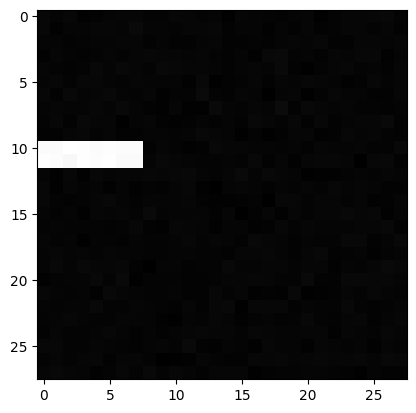

In [ ]:
stroke_sample = np.reshape(mnist_nn.weights[0][:, 15], (28, 28))
plt.imshow(stroke_sample, cmap=plt.cm.gray)
mnist_nn.weights[0][0, :]

Let's restart our training, but have some aggressive learning rate to find a better valley.

In [ ]:
for i in range(100):
    sample_indices = np.random.choice(range(60000), size=50, replace=False)
    training_sample_x = x_train_array[sample_indices, :]
    training_sample_y = y_train_array[sample_indices, :]
    mnist_nn.backpropagation(training_sample_x, training_sample_y, learning_rate = 0.1, rel_noise = 1)
    print(f"Training iteration {i+1}:")
    error = mnist_nn.error(testing_sample_x, testing_sample_y)
    print(f"Average error: {error}")
    if error < 0.4:
        break

Training iteration 1:
Average error: 1.0
Training iteration 2:
Average error: 1.0
Training iteration 3:
Average error: 1.0
Training iteration 4:
Average error: 1.0
Training iteration 5:
Average error: 1.0
Training iteration 6:
Average error: 1.0
Training iteration 7:
Average error: 1.0
Training iteration 8:
Average error: 1.0
Training iteration 9:
Average error: 1.0
Training iteration 10:
Average error: 1.0
Training iteration 11:
Average error: 1.0
Training iteration 12:
Average error: 1.0
Training iteration 13:
Average error: 1.0
Training iteration 14:
Average error: 1.0
Training iteration 15:
Average error: 1.0
Training iteration 16:
Average error: 1.0
Training iteration 17:
Average error: 1.0
Training iteration 18:
Average error: 1.0
Training iteration 19:
Average error: 1.0
Training iteration 20:
Average error: 1.0
Training iteration 21:
Average error: 1.0
Training iteration 22:
Average error: 1.0
Training iteration 23:
Average error: 1.0
Training iteration 24:
Average error: 1.0
T

Oh no! We've hit a point where the error produces 1.0 each time. And considering our function is ReLU, the derivative of the function at negative points is zero, causing a lot of activations to produce deep negative values. If we look carefully at what's going on, we can try to diagnose the problem.

In [ ]:
mnist_nn.weights

[array([[ 1.1087747 ,  1.03905602,  0.82992833, ..., -0.35040479,
          0.08253052, -0.30993595],
        [ 0.90197988,  0.88697186,  0.88071155, ..., -0.22347623,
          0.06860871, -0.3946    ],
        [ 1.25970222,  0.0454571 ,  0.24129716, ...,  0.04869249,
         -0.07632678,  0.20357664],
        ...,
        [ 0.02971567,  0.14360226, -0.11685215, ..., -0.43066214,
          0.13147628,  0.01015206],
        [ 0.04819312, -0.02570559,  0.02391902, ...,  0.12141521,
          1.07373293,  0.01155393],
        [-0.0961793 ,  0.14068556, -0.05462502, ..., -0.07923231,
          0.9384157 , -0.06868944]]),
 array([[ 0.10564722,  0.0583489 ,  0.31891026, ...,  0.10264285,
         -0.13766751,  0.01045019],
        [ 0.12150051, -0.05700933,  0.26145787, ...,  0.23811822,
          0.26286984,  0.00546335],
        [-0.13166881, -0.2843134 , -0.10011221, ..., -0.14235037,
         -0.08917861, -0.35552762],
        ...,
        [-0.12462751, -0.28386823, -0.06256191, ...,  

In [ ]:
mnist_nn.biases

[array([ 3.87068611e-01, -3.53090546e-02,  4.42769052e-02,  3.18053498e-01,
        -1.96306287e-01, -2.06851298e-01,  1.37115060e-01, -4.72479774e-03,
        -5.69775492e-02,  5.19238476e-02,  1.56870658e-01, -7.99650024e-02,
         1.52282851e-01, -5.91833092e-02,  2.96942727e-02, -1.33015839e-01,
         1.14025829e-02, -3.30978434e-02, -8.40424885e-05, -1.77309615e-02,
        -9.73532674e-02, -2.38827355e-01, -1.52974402e-01,  4.58743305e-03,
        -3.09596462e-01,  2.99104215e-01,  3.28887501e-01,  1.18437111e-01,
        -1.89444752e-01,  1.32126941e-01, -1.15899612e-01, -2.18383166e-02,
         3.24071838e-01,  2.24936554e-01, -1.84699036e-02,  4.28927810e-02,
         3.14886686e-01,  2.35495498e-01,  1.03413013e-02, -1.89673101e-01,
         2.03527859e-01,  4.03646230e-02,  9.85418001e-02,  8.07505009e-02,
        -1.47446076e-01, -3.52337944e-02,  4.42646999e-01, -8.46077352e-02,
        -7.17623068e-02,  4.45494709e-01,  2.90236616e-01, -2.26409844e-01,
         1.3

It's not easy to see, but especially at the final matrix, there are a lot of values towards the negative side. It may be time for a reset, or to change our activation function. How about this: Let's try using sigmoid as our activation function now. We'll make some changes to our settings.

In [ ]:
mnist_nn.activation = sigmoid
mnist_nn.d_activation = d_sigmoid
mnist_nn.inv_activation = inv_sigmoid

Let's try again.

In [ ]:
for i in range(100):
    sample_indices = np.random.choice(range(60000), size=50, replace=False)
    training_sample_x = x_train_array[sample_indices, :]
    training_sample_y = y_train_array[sample_indices, :]
    mnist_nn.backpropagation(training_sample_x, training_sample_y, learning_rate = 0.1, rel_noise = 1)
    print(f"Training iteration {i+1}:")
    error = mnist_nn.error(testing_sample_x, testing_sample_y)
    print(f"Average error: {error}")
    if error < 0.4:
        break

Training iteration 1:
Average error: 0.9966315265027782
Training iteration 2:
Average error: 0.9966267912572144
Training iteration 3:
Average error: 0.9966889051951288
Training iteration 4:
Average error: 0.9966696752535329
Training iteration 5:
Average error: 0.9967030118803882
Training iteration 6:
Average error: 0.9967836844608188
Training iteration 7:
Average error: 0.9966263434496636
Training iteration 8:
Average error: 0.9965208366780537
Training iteration 9:
Average error: 0.9965826380466827
Training iteration 10:
Average error: 0.9966285053501861
Training iteration 11:
Average error: 0.9965853616762905
Training iteration 12:
Average error: 0.9964534476649078
Training iteration 13:
Average error: 0.9964323881389708
Training iteration 14:
Average error: 0.9963968148197402
Training iteration 15:
Average error: 0.9963318231712919
Training iteration 16:
Average error: 0.9962169222907516
Training iteration 17:
Average error: 0.9962335760791529
Training iteration 18:
Average error: 0.

In [ ]:
for i in range(100):
    sample_indices = np.random.choice(range(60000), size=50, replace=False)
    training_sample_x = x_train_array[sample_indices, :]
    training_sample_y = y_train_array[sample_indices, :]
    mnist_nn.backpropagation(training_sample_x, training_sample_y, learning_rate = 1, rel_noise = 1)
    print(f"Training iteration {i+1}:")
    error = mnist_nn.error(testing_sample_x, testing_sample_y)
    print(f"Average error: {error}")
    if error < 0.4:
        break

Using the sigmoid helps a little bit, but it seems it will take a long time for us to get the neurons back.

In [ ]:
for i in range(1000):
    sample_indices = np.random.choice(range(60000), size=10, replace=False)
    training_sample_x = x_train_array[sample_indices, :]
    training_sample_y = y_train_array[sample_indices, :]
    mnist_nn.backpropagation(training_sample_x, training_sample_y, learning_rate = 1, rel_noise = 1)
    print(f"Training iteration {i+1}:")
    error = mnist_nn.error(testing_sample_x, testing_sample_y)
    print(f"Average error: {error}")
    if error < 0.4:
        break

Training iteration 1:
Average error: 0.9973735725419621
Training iteration 2:
Average error: 0.9977111286581797
Training iteration 3:
Average error: 0.997294805686918
Training iteration 4:
Average error: 0.9975858556845619
Training iteration 5:
Average error: 0.9973798767651434
Training iteration 6:
Average error: 0.9961848842571922
Training iteration 7:
Average error: 0.9939581394617505
Training iteration 8:
Average error: 0.9887454841127198
Training iteration 9:
Average error: 0.9942793848926241
Training iteration 10:
Average error: 0.9937860454257859
Training iteration 11:
Average error: 0.9920729998192563
Training iteration 12:
Average error: 0.991533149551962
Training iteration 13:
Average error: 0.9912365188464637
Training iteration 14:
Average error: 0.9859886347828728
Training iteration 15:
Average error: 0.9879503988468846
Training iteration 16:
Average error: 0.9889652256051642
Training iteration 17:
Average error: 0.9919646747619134
Training iteration 18:
Average error: 0.99

It may help to reset the weights to more moderate values if you get stuck.

In [ ]:
[weight.shape for weight in mnist_nn.weights]

[(784, 550), (550, 100), (100, 40), (40, 10)]

In [ ]:
stroke_set_array

array([[ 0.49370958, -0.99888035, -1.32971652, ..., -2.26642349,
        -5.09886342,  0.18719851],
       [ 4.31227606,  3.47565911, -2.19371645, ..., -2.6671835 ,
         1.08775996, -1.73142009],
       [ 5.04531883,  0.0730112 ,  2.30348974, ...,  0.97402743,
         0.14540658, -1.68436645],
       ...,
       [ 4.64577153,  0.85557191, -3.08190319, ..., -5.46798007,
        -1.98856982, -3.81951066],
       [-0.07307027, -0.64629752, -1.49544948, ...,  1.64655245,
         0.73221514,  2.91760217],
       [-4.37297573, -0.49957377, -5.01650358, ...,  2.47216691,
         3.05301215, -1.83785191]])

In [ ]:
mnist_nn.set_weight(0, stroke_set_array)
mnist_nn.set_weight(1, np.random.normal(scale=0.1, size=mnist_nn.weights[1].shape))
mnist_nn.set_weight(2, np.random.normal(scale=0.1, size=mnist_nn.weights[2].shape))
mnist_nn.set_weight(3, np.random.normal(scale=0.1, size=mnist_nn.weights[3].shape))

mnist_nn.set_bias(0, np.random.normal(scale=0.1, size=mnist_nn.biases[0].shape))
mnist_nn.set_bias(1, np.random.normal(scale=0.1, size=mnist_nn.biases[1].shape))
mnist_nn.set_bias(2, np.random.normal(scale=0.1, size=mnist_nn.biases[2].shape))
mnist_nn.set_bias(3, np.random.normal(scale=0.1, size=mnist_nn.biases[3].shape))

mnist_nn.valid_state()

True

In [ ]:
for i in range(100):
    sample_indices = np.random.choice(range(60000), size=20, replace=False)
    training_sample_x = x_train_array[sample_indices, :]
    training_sample_y = y_train_array[sample_indices, :]
    mnist_nn.backpropagation(training_sample_x, training_sample_y, learning_rate = 0.1, rel_noise = 0)
    print(f"Training iteration {i+1}:")
    error = mnist_nn.error(testing_sample_x, testing_sample_y)
    print(f"Average error: {error}")
    if error < 0.4:
        break

Training iteration 1:
Average error: 2.5013205140184542
Training iteration 2:
Average error: 2.5073203654916933
Training iteration 3:
Average error: 2.4942018763724594
Training iteration 4:
Average error: 2.5003484451012734
Training iteration 5:
Average error: 2.50203719851608
Training iteration 6:
Average error: 2.4987930458849648
Training iteration 7:
Average error: 2.4939785481731276
Training iteration 8:
Average error: 2.5031332786635674
Training iteration 9:
Average error: 2.495746426633601
Training iteration 10:
Average error: 2.500877298308056
Training iteration 11:
Average error: 2.501608638011946
Training iteration 12:
Average error: 2.497739483250096
Training iteration 13:
Average error: 2.501134424967252
Training iteration 14:
Average error: 2.4977344002701614
Training iteration 15:
Average error: 2.5012501020403346
Training iteration 16:
Average error: 2.496330082590714
Training iteration 17:
Average error: 2.5028333699484957
Training iteration 18:
Average error: 2.49593686

C:\Users\rayng\AppData\Local\Temp\ipykernel_36856\4276526290.py:2: RuntimeWarning: overflow encountered in exp
  return 1/(1 + np.exp(-x))


Training iteration 54:
Average error: 2.501289525124876
Training iteration 55:
Average error: 2.499431745864971
Training iteration 56:
Average error: 2.499861926943986
Training iteration 57:
Average error: 2.4967316850036605
Training iteration 58:
Average error: 2.507117235893267
Training iteration 59:
Average error: 2.4966878906235475
Training iteration 60:
Average error: 2.501644836716193
Training iteration 61:
Average error: 2.5031771527088194
Training iteration 62:
Average error: 2.4967980398364453
Training iteration 63:
Average error: 2.492948823652313
Training iteration 64:
Average error: 2.5049261261481166
Training iteration 65:
Average error: 2.498901353569438
Training iteration 66:
Average error: 2.501774977043668
Training iteration 67:
Average error: 2.494885079870153
Training iteration 68:
Average error: 2.5005073071874917
Training iteration 69:
Average error: 2.493315238132384
Training iteration 70:
Average error: 2.505074296915764
Training iteration 71:
Average error: 2.49

In [ ]:
mnist_nn.forward(x_train_array[0])

([array([0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0

In [ ]:
correct_answers = 0
for index in test_indices:
    output = mnist_nn.forward(x_test_array[index, :])[0][-1]
    prediction = np.argmax(output)
    if prediction == y_test[index]:
        correct_answers += 1

print(correct_answers)

10


C:\Users\rayng\AppData\Local\Temp\ipykernel_36856\4276526290.py:2: RuntimeWarning: overflow encountered in exp
  return 1/(1 + np.exp(-x))


---

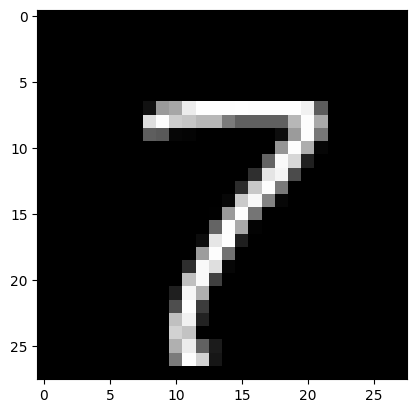

In [ ]:
stroke_sample = np.reshape(x_train_array[43710], (28, 28))
plt.imshow(stroke_sample, cmap=plt.cm.gray)

In [ ]:
mnist_nn2.set_weight(0, stroke_set_array.copy() / 20)

In [ ]:
mnist_nn2.weights

[array([[0.05, 0.05, 0.05, ..., 0.  , 0.  , 0.  ],
        [0.05, 0.05, 0.05, ..., 0.  , 0.  , 0.  ],
        [0.05, 0.  , 0.  , ..., 0.  , 0.  , 0.  ],
        ...,
        [0.  , 0.  , 0.  , ..., 0.  , 0.  , 0.  ],
        [0.  , 0.  , 0.  , ..., 0.  , 0.05, 0.  ],
        [0.  , 0.  , 0.  , ..., 0.  , 0.05, 0.  ]]),
 array([[ 0.06342485, -0.04811233, -0.00531066, ...,  0.12713373,
         -0.01365732,  0.03929305],
        [ 0.00283486,  0.02580971,  0.11777197, ..., -0.0016521 ,
          0.02623866, -0.07244882],
        [-0.1666812 , -0.10670228, -0.05052389, ...,  0.06212173,
         -0.08302569,  0.06681427],
        ...,
        [-0.05618637, -0.07743614, -0.07860368, ...,  0.10576068,
          0.0286234 ,  0.21443945],
        [-0.05097395,  0.00518406, -0.04687313, ...,  0.13441076,
         -0.07286768,  0.05977086],
        [-0.05859803,  0.04030207, -0.027623  , ...,  0.06881594,
          0.01266336, -0.02475791]]),
 array([[-0.04597554, -0.06309153, -0.11405585,  0.0

In [ ]:
mnist_nn2.forward(x_train_array[43710])

([array([0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0

In [ ]:
test_indices = np.random.choice(range(10000), size=100, replace=False)

testing_sample_x = x_test_array[test_indices, :]
testing_sample_y = y_test_array[test_indices, :]

Let's see how the error trends with a plot.

Training iteration 20...
Training iteration 40...
Training iteration 60...
Training iteration 80...
Training iteration 100...
Training iteration 120...
Training iteration 140...
Training iteration 160...
Training iteration 180...
Training iteration 200...
Training iteration 220...
Training iteration 240...
Training iteration 260...
Training iteration 280...
Training iteration 300...
Training iteration 320...
Training iteration 340...
Training iteration 360...
Training iteration 380...
Training iteration 400...
Training iteration 420...
Training iteration 440...
Training iteration 460...
Training iteration 480...
Training iteration 500...
Training iteration 520...
Training iteration 540...
Training iteration 560...
Training iteration 580...
Training iteration 600...
Training iteration 620...
Training iteration 640...
Training iteration 660...
Training iteration 680...
Training iteration 700...
Training iteration 720...
Training iteration 740...
Training iteration 760...
Training iterati

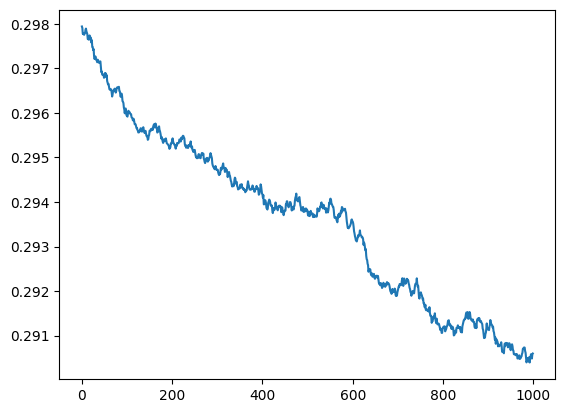

In [ ]:
error_history = []

for i in range(1000):
    sample_indices = np.random.choice(range(60000), size=20, replace=False)
    training_sample_x = x_train_array[sample_indices, :]
    training_sample_y = y_train_array[sample_indices, :] * 0.6 + 0.3
    mnist_nn2.backpropagation(training_sample_x, training_sample_y, learning_rate = 0.01, rel_noise = 0.0)
    #print(f"Training iteration {i+1}:")
    if i % 20 == 19:
        print(f"Training iteration {i+1}...")
    error = mnist_nn2.error(testing_sample_x, testing_sample_y * 0.6 + 0.3)
    #print(f"Average error: {error}")
    error_history.append(error)
    if error < 0.25:
        break

plt.plot(error_history)

A beautiful result we want to see. The error is trending downwards.

But how many of each digit is the neural network getting right?

In [ ]:
test_indices = np.random.choice(range(10000), size=1000, replace=False)

testing_sample_x = x_test_array[test_indices, :]
testing_sample_y = y_test_array[test_indices, :]

In [ ]:
correct_answers = 0
questions_by_digit = {n: 0 for n in range(0,10)}
correct_answers_by_digit = {n: 0 for n in range(0,10)}
for index in test_indices:
    questions_by_digit[y_test[index]] += 1
    output = mnist_nn2.forward(x_test_array[index, :])[0][-1]
    prediction = np.argmax(output)
    if prediction == y_test[index]:
        correct_answers += 1
        correct_answers_by_digit[y_test[index]] += 1
rate_by_digit = {n: correct_answers_by_digit[n] / questions_by_digit[n] for n in range(10)}

print(correct_answers)
print(questions_by_digit)
print(correct_answers_by_digit)
print(rate_by_digit)

588
{0: 95, 1: 121, 2: 112, 3: 106, 4: 83, 5: 90, 6: 99, 7: 111, 8: 90, 9: 93}
{0: 94, 1: 121, 2: 62, 3: 81, 4: 38, 5: 0, 6: 60, 7: 96, 8: 24, 9: 12}
{0: 0.9894736842105263, 1: 1.0, 2: 0.5535714285714286, 3: 0.7641509433962265, 4: 0.4578313253012048, 5: 0.0, 6: 0.6060606060606061, 7: 0.8648648648648649, 8: 0.26666666666666666, 9: 0.12903225806451613}


<BarContainer object of 10 artists>

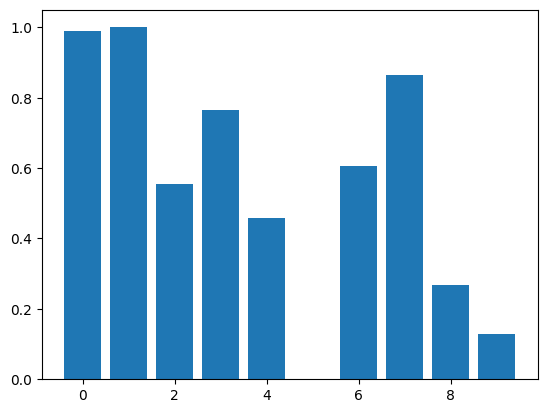

In [ ]:
plt.bar(rate_by_digit.keys(), rate_by_digit.values())

This neural network is showing varying results on each digit. For example, it recognizes 0s, 1s, and 7s very well, but it does poorly on 5s, 8s, and 9s as it has a hard time recognizing these particular digits. They do have a complex shape too at that.

So let's try a new training regimen: What if we focus on digits that the model is not performing well at?

In [ ]:
training_digit_indices = {n: [] for n in range(10)}

for i in range(60000):
    digit = y_train[i]
    training_digit_indices[digit].append(i)

In [ ]:
cero = training_digit_indices[0]
uno = training_digit_indices[1]
dos = training_digit_indices[2]
tres = training_digit_indices[3]
cuatro = training_digit_indices[4]
cinco = training_digit_indices[5]
seis = training_digit_indices[6]
siete = training_digit_indices[7]
ocho = training_digit_indices[8]
nueve = training_digit_indices[9]

In [ ]:
cero_sample = np.random.choice(cero, 10, replace=False)
uno_sample = np.random.choice(uno, 10, replace=False)
dos_sample = np.random.choice(dos, 10, replace=False)
tres_sample = np.random.choice(tres, 10, replace=False)
cuatro_sample = np.random.choice(cuatro, 10, replace=False)
cinco_sample = np.random.choice(cinco, 10, replace=False)
seis_sample = np.random.choice(seis, 10, replace=False)
siete_sample = np.random.choice(siete, 10, replace=False)
ocho_sample = np.random.choice(ocho, 10, replace=False)
nueve_sample = np.random.choice(nueve, 10, replace=False)

In [ ]:
error_history = []

probabilities = np.zeros(60000)
probabilities[np.concatenate((cero, uno, tres, siete))] = 2
probabilities[np.concatenate((dos, ocho, nueve))] = 3
probabilities[np.concatenate((cuatro, cinco, seis))] = 4
probabilities /= np.sum(probabilities)

test_indices = np.random.choice(range(10000), size=1000, replace=False)

testing_sample_x = x_test_array[test_indices, :]
testing_sample_y = y_test_array[test_indices, :]

correct_answers = 0
questions_by_digit = {n: 0 for n in range(0,10)}
correct_answers_by_digit = {n: 0 for n in range(0,10)}

for i in range(100):
    sample_indices = np.random.choice(range(60000), size=20, replace=False, p=probabilities)
    training_sample_x = x_train_array[sample_indices, :]
    training_sample_y = y_train_array[sample_indices, :] * 0.6 + 0.3
    mnist_nn2.backpropagation(training_sample_x, training_sample_y, learning_rate = 0.01, rel_noise = 0.0)
    #print(f"Training iteration {i+1}:")
    if i % 10 == 9:
        print(f"Training iteration {i+1}...")
    error = mnist_nn2.error(testing_sample_x, testing_sample_y * 0.6 + 0.3)
    #print(f"Average error: {error}")
    error_history.append(error)
    if error < 0.25:
        break

for index in test_indices:
    questions_by_digit[y_test[index]] += 1
    output = mnist_nn2.forward(x_test_array[index, :])[0][-1]
    prediction = np.argmax(output)
    if prediction == y_test[index]:
        correct_answers += 1
        correct_answers_by_digit[y_test[index]] += 1
rate_by_digit = {n: correct_answers_by_digit[n] / questions_by_digit[n] for n in range(10)}

Training iteration 10...
Training iteration 20...
Training iteration 30...
Training iteration 40...
Training iteration 50...
Training iteration 60...
Training iteration 70...
Training iteration 80...
Training iteration 90...
Training iteration 100...


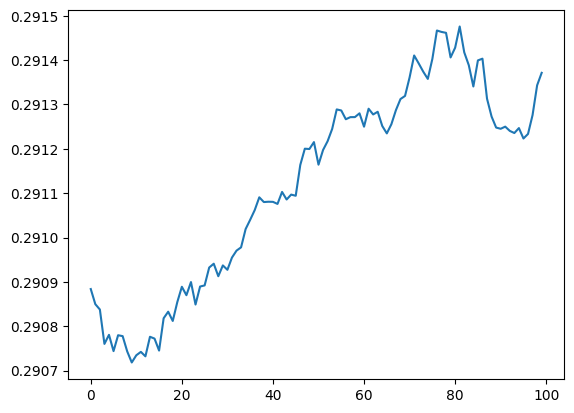

In [ ]:
plt.plot(error_history)

<BarContainer object of 10 artists>

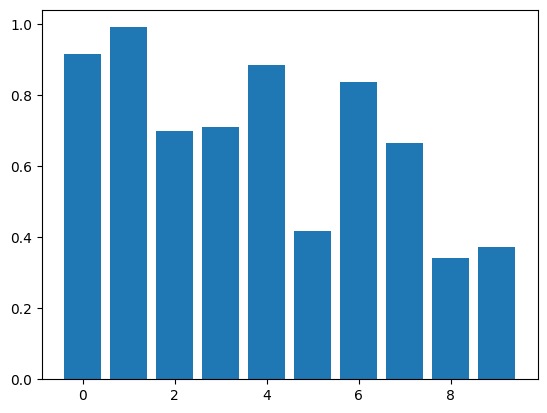

In [ ]:
plt.bar(rate_by_digit.keys(), rate_by_digit.values())

In [ ]:
correct_answers

692

Turns out that increasing the probabilities for worse performing digits makes it do better at those ones in particular. But we need to be careful not to exclude the other digits as this will lead to the phenomenon of *catastrophic forgetting* - it forgets other digits and thus it will not be able to recognize those forgotten digits because it was too focused on the ones you make it focus on.

By the way, we should save our weights and biases so we can access them later.

In [ ]:
import pickle
import datetime

In [ ]:
filename = f"mnist_nn_weights_{datetime.datetime.now().strftime('%Y-%m-%d_%H-%M-%S')}.pkl"
pickle.dump(mnist_nn2.weights, open(filename, 'wb'))

filename = f"mnist_nn_biases_{datetime.datetime.now().strftime('%Y-%m-%d_%H-%M-%S')}.pkl"
pickle.dump(mnist_nn2.biases, open(filename, 'wb'))

In [ ]:
mnist_nn3 = NeuralNetwork([784, 550, 50, 10], sigma=0.0, activation=sigmoid, d_activation=d_sigmoid)

biases = pickle.load(open("mnist_nn_biases_2026-03-19_19-20-57.pkl", 'rb'))
mnist_nn3.biases = biases

weights = pickle.load(open("mnist_nn_weights_2026-03-19_19-20-57.pkl", 'rb'))
mnist_nn3.weights = weights

<BarContainer object of 10 artists>

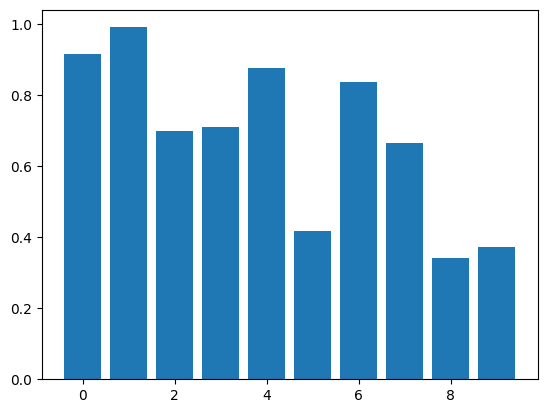

In [ ]:
for index in test_indices:
    questions_by_digit[y_test[index]] += 1
    output = mnist_nn3.forward(x_test_array[index, :])[0][-1]
    prediction = np.argmax(output)
    if prediction == y_test[index]:
        correct_answers += 1
        correct_answers_by_digit[y_test[index]] += 1
rate_by_digit = {n: correct_answers_by_digit[n] / questions_by_digit[n] for n in range(10)}

plt.bar(rate_by_digit.keys(), rate_by_digit.values())

In [ ]:
np.argsort(list(rate_by_digit.values()))

array([8, 9, 5, 7, 2, 3, 6, 4, 0, 1], dtype=int64)

Let's make this training dynamic now by automating this process of prioritizing the digits.

In [ ]:
def test_nn(nn, test_indices):
    correct_answers = 0
    questions_by_digit = {n: 0 for n in range(0,10)}
    correct_answers_by_digit = {n: 0 for n in range(0,10)}

    for index in test_indices:
        questions_by_digit[y_test[index]] += 1
        output = nn.forward(x_test_array[index, :])[0][-1]
        prediction = np.argmax(output)
        if prediction == y_test[index]:
            correct_answers += 1
            correct_answers_by_digit[y_test[index]] += 1
    rate_by_digit = {n: correct_answers_by_digit[n] / questions_by_digit[n] for n in range(10)}
    return correct_answers, questions_by_digit, correct_answers_by_digit, rate_by_digit

In [ ]:
error_history = []

test_indices = np.random.choice(range(10000), size=1000, replace=False)

testing_sample_x = x_test_array[test_indices, :]
testing_sample_y = y_test_array[test_indices, :]

digit_sets = [cero, uno, dos, tres, cuatro, cinco, seis, siete, ocho, nueve]

for i in range(200):
    if i % 20 == 0:
        print("Testing model and calibrating training regimen...")
        validation_indices = np.random.choice(range(10000), size=1000, replace=False)

        correct_answers, questions_by_digit, correct_answers_by_digit, rate_by_digit = test_nn(mnist_nn2, validation_indices)

        digits_order = np.argsort(list(rate_by_digit.values()))
        high_priority = [digit_sets[n] for n in digits_order[0:2]]
        medium_priority = [digit_sets[n] for n in digits_order[2:5]]
        low_priority = [digit_sets[n] for n in digits_order[5:10]]

        probabilities = np.zeros(60000)
        probabilities[np.concatenate(high_priority)] = 4
        probabilities[np.concatenate(medium_priority)] = 3
        probabilities[np.concatenate(low_priority)] = 2
        probabilities /= np.sum(probabilities)
        
    sample_indices = np.random.choice(range(60000), size=20, replace=False, p=probabilities)
    training_sample_x = x_train_array[sample_indices, :]
    training_sample_y = y_train_array[sample_indices, :] * 0.6 + 0.3
    mnist_nn2.backpropagation(training_sample_x, training_sample_y, learning_rate = 0.01, rel_noise = 0.0)
    if i % 10 == 9:
        print(f"Training iteration {i+1}...")
    error = mnist_nn2.error(testing_sample_x, testing_sample_y * 0.6 + 0.3)
    error_history.append(error)
    if error < 0.25:
        break

correct_answers, questions_by_digit, correct_answers_by_digit, rate_by_digit = test_nn(mnist_nn2, test_indices)

Testing model and calibrating training regimen...
Training iteration 10...
Training iteration 20...
Testing model and calibrating training regimen...
Training iteration 30...
Training iteration 40...
Testing model and calibrating training regimen...
Training iteration 50...
Training iteration 60...
Testing model and calibrating training regimen...
Training iteration 70...
Training iteration 80...
Testing model and calibrating training regimen...
Training iteration 90...
Training iteration 100...
Testing model and calibrating training regimen...
Training iteration 110...
Training iteration 120...
Testing model and calibrating training regimen...
Training iteration 130...
Training iteration 140...
Testing model and calibrating training regimen...
Training iteration 150...
Training iteration 160...
Testing model and calibrating training regimen...
Training iteration 170...
Training iteration 180...
Testing model and calibrating training regimen...
Training iteration 190...
Training iterat

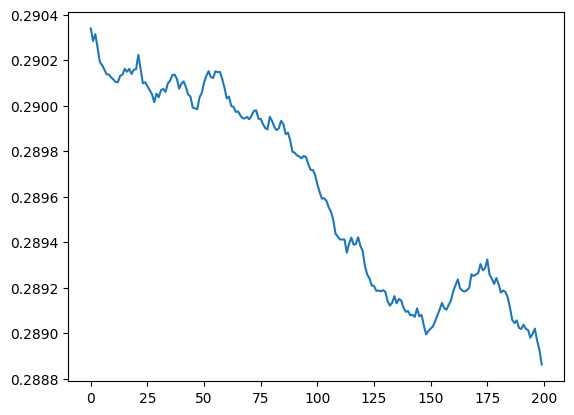

In [ ]:
plt.plot(error_history)

<BarContainer object of 10 artists>

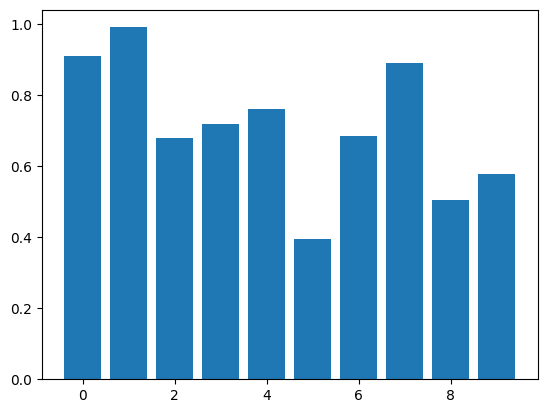

In [ ]:
plt.bar(rate_by_digit.keys(), rate_by_digit.values())

In [ ]:
correct_answers

717

How did the model perform? It seems to have worked well and shows a balance in the digit recognition rate as well as a decreasing trend. Let's run the same thing one more time, and see how things change. But first, let's save the parameters.

In [ ]:
filename = f"mnist_nn_weights_{datetime.datetime.now().strftime('%Y-%m-%d_%H-%M-%S')}.pkl"
pickle.dump(mnist_nn2.weights, open(filename, 'wb'))

filename = f"mnist_nn_biases_{datetime.datetime.now().strftime('%Y-%m-%d_%H-%M-%S')}.pkl"
pickle.dump(mnist_nn2.biases, open(filename, 'wb'))

Testing model and calibrating training regimen...
Training iteration 10...
Training iteration 20...
Testing model and calibrating training regimen...
Training iteration 30...
Training iteration 40...
Testing model and calibrating training regimen...
Training iteration 50...
Training iteration 60...
Testing model and calibrating training regimen...
Training iteration 70...
Training iteration 80...
Testing model and calibrating training regimen...
Training iteration 90...
Training iteration 100...
Testing model and calibrating training regimen...
Training iteration 110...
Training iteration 120...
Testing model and calibrating training regimen...
Training iteration 130...
Training iteration 140...
Testing model and calibrating training regimen...
Training iteration 150...
Training iteration 160...
Testing model and calibrating training regimen...
Training iteration 170...
Training iteration 180...
Testing model and calibrating training regimen...
Training iteration 190...
Training iterat

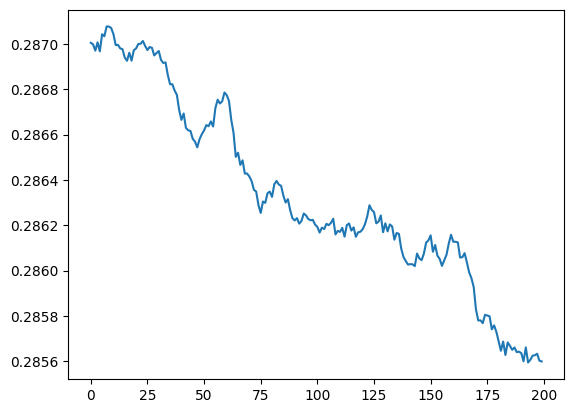

In [ ]:
error_history = []

test_indices = np.random.choice(range(10000), size=1000, replace=False)

testing_sample_x = x_test_array[test_indices, :]
testing_sample_y = y_test_array[test_indices, :]

digit_sets = [cero, uno, dos, tres, cuatro, cinco, seis, siete, ocho, nueve]

for i in range(200):
    if i % 20 == 0:
        print("Testing model and calibrating training regimen...")
        validation_indices = np.random.choice(range(10000), size=1000, replace=False)

        correct_answers, questions_by_digit, correct_answers_by_digit, rate_by_digit = test_nn(mnist_nn2, validation_indices)

        digits_order = np.argsort(list(rate_by_digit.values()))
        high_priority = [digit_sets[n] for n in digits_order[0:2]]
        medium_priority = [digit_sets[n] for n in digits_order[2:5]]
        low_priority = [digit_sets[n] for n in digits_order[5:10]]

        probabilities = np.zeros(60000)
        probabilities[np.concatenate(high_priority)] = 4
        probabilities[np.concatenate(medium_priority)] = 3
        probabilities[np.concatenate(low_priority)] = 2
        probabilities /= np.sum(probabilities)
        
    sample_indices = np.random.choice(range(60000), size=20, replace=False, p=probabilities)
    training_sample_x = x_train_array[sample_indices, :]
    training_sample_y = y_train_array[sample_indices, :] * 0.6 + 0.3
    mnist_nn2.backpropagation(training_sample_x, training_sample_y, learning_rate = 0.01, rel_noise = 0.0)
    if i % 10 == 9:
        print(f"Training iteration {i+1}...")
    error = mnist_nn2.error(testing_sample_x, testing_sample_y * 0.6 + 0.3)
    error_history.append(error)
    if error < 0.25:
        break

correct_answers, questions_by_digit, correct_answers_by_digit, rate_by_digit = test_nn(mnist_nn2, test_indices)

plt.plot(error_history)

<BarContainer object of 10 artists>

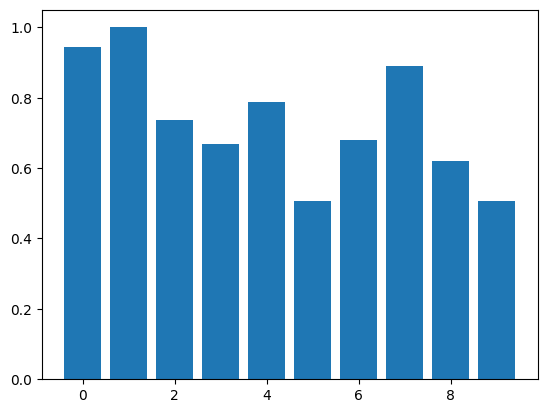

In [ ]:
plt.bar(rate_by_digit.keys(), rate_by_digit.values())

In [ ]:
rate_by_digit

{0: 0.9444444444444444,
 1: 1.0,
 2: 0.7372881355932204,
 3: 0.6698113207547169,
 4: 0.7884615384615384,
 5: 0.5061728395061729,
 6: 0.68,
 7: 0.8901098901098901,
 8: 0.6195652173913043,
 9: 0.5051546391752577}

In [ ]:
correct_answers

742

This run gave us quite an improved result, with a recognition rate of over 50% for each digit. And our correct answers is reaching 742/1000. As usual, the error is trending downwards.

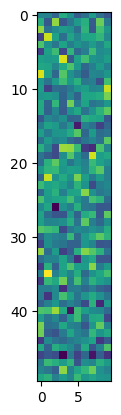

In [ ]:
plt.imshow(mnist_nn2.weights[2])